<a href="https://colab.research.google.com/github/Yassminefeki/brain-tumor-mlops/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Exploratory data analysis

Figures for the *Dataset* part of the presentation. Run after `dvc repro` (or `dvc pull`).
Every figure is saved to `reports/figures/`.

In [2]:
# Setup: only does something on Google Colab. Locally (Jupyter / VS Code with the .venv
# kernel) the project is already installed and the data is in data/, so this cell is a no-op.
import os
import sys

if "google.colab" in sys.modules:
    from google.colab import userdata

    GITHUB_USER, REPO = "Yassminefeki", "brain-tumor-mlops"
    token = userdata.get("GITHUB_TOKEN")  # Colab secret, needed while the repo is private
    if not os.path.exists(f"/content/{REPO}"):
        !git clone -q https://{token}@github.com/{GITHUB_USER}/{REPO}.git /content/{REPO}
    %cd /content/{REPO}
    !git pull -q
    !pip install -q -e .
    sys.path.insert(0, f"/content/{REPO}/src")  # make the fresh install importable now
    if not os.path.exists("data/splits.csv"):
        !dvc repro  # rebuilds the dataset from Figshare (~5-10 min)

/content/brain-tumor-mlops
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for brain-tumor-mlops (pyproject.toml) ... done
Running stage 'download':
> python -m brain_tumor.data.ingest download
19:40:18 | INFO    | brain_tumor.ingest | Downloading brainTumorDataPublic_1-766.zip (204.5 MiB)
19:40:21 | INFO    | brain_tumor.ingest | Downloading brainTumorDataPublic_1533-2298.zip (205.6 MiB)
19:40:26 | INFO    | brain_tumor.ingest | Downloading brainTumorDataPublic_767-1532.zip (207.8 MiB)
19:40:30 | INFO    | brain_tumor.ingest | Downloading brainTumorDataPublic_2299-3064.zip (220.9 MiB)
19:40:33 | INFO    | brain_tumor.ingest | Downloading cvind.mat (0.0 MiB)
19:40:33 | INFO   

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from brain_tumor.config import load_params, project_path

cfg = load_params()
CLASSES = cfg["data"]["class_names"]
FIG_DIR = project_path(cfg, "reports_dir") / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

meta = pd.read_csv(project_path(cfg, "metadata"), dtype={"patient_id": str})
splits = pd.read_csv(project_path(cfg, "splits"), dtype={"patient_id": str})
processed = project_path(cfg, "processed_dir")
meta.head()

,image_id,file,label,class_name,patient_id,height,width,min,max,mean,tumor_area
0,1,1.mat,0,meningioma,100360,512,512,0.0,3366.0,441.478424,4569
1,2,2.mat,0,meningioma,100360,512,512,0.0,3626.0,456.342766,8630
2,3,3.mat,0,meningioma,100360,512,512,0.0,3695.0,480.216778,10511
3,4,4.mat,0,meningioma,100360,512,512,0.0,4196.0,477.403244,8897
4,5,5.mat,0,meningioma,100360,512,512,0.0,3948.0,468.226776,11250


## 1. Class balance — images and patients

,images,patients,images_per_patient
class_name,,,
meningioma,708,82,8.6
glioma,1426,89,16.0
pituitary,930,62,15.0


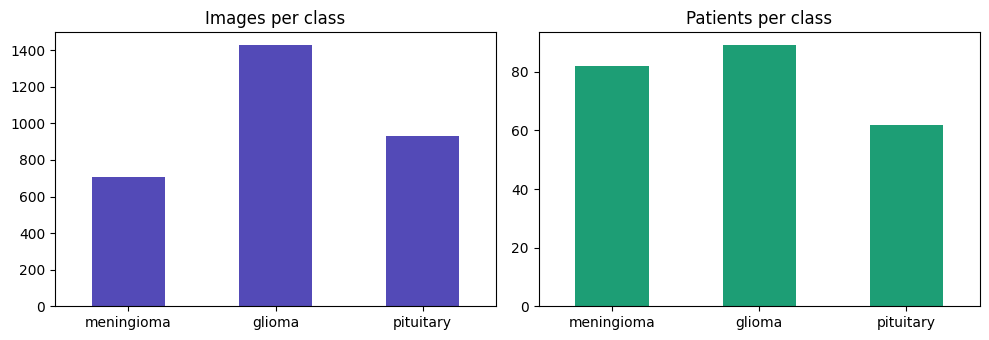

In [4]:
per_class = meta.groupby("class_name").agg(images=("image_id", "size"),
                                           patients=("patient_id", "nunique")).loc[CLASSES]
per_class["images_per_patient"] = (per_class["images"] / per_class["patients"]).round(1)
display(per_class)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
per_class["images"].plot.bar(ax=axes[0], color="#534AB7", title="Images per class")
per_class["patients"].plot.bar(ax=axes[1], color="#1D9E75", title="Patients per class")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "class_balance.png", dpi=150)

## 2. Images per patient — why the split must be patient-level

Each patient contributes many slices. A random image split would put slices of the same
patient in both train and test.

3064 images / 233 patients -> mean 13.2, median 13, max 38


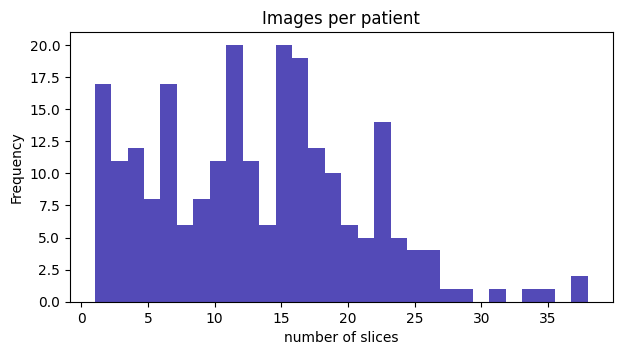

In [5]:
ipp = meta.groupby("patient_id").size()
print(f"{len(meta)} images / {len(ipp)} patients -> mean {ipp.mean():.1f}, median {ipp.median():.0f}, max {ipp.max()}")
ax = ipp.plot.hist(bins=30, color="#534AB7", figsize=(7, 3.5), title="Images per patient")
ax.set_xlabel("number of slices")
ax.figure.savefig(FIG_DIR / "images_per_patient.png", dpi=150, bbox_inches="tight")

## 3. Image sizes and intensity range

,,images
height,width,
256,256,15
512,512,3049


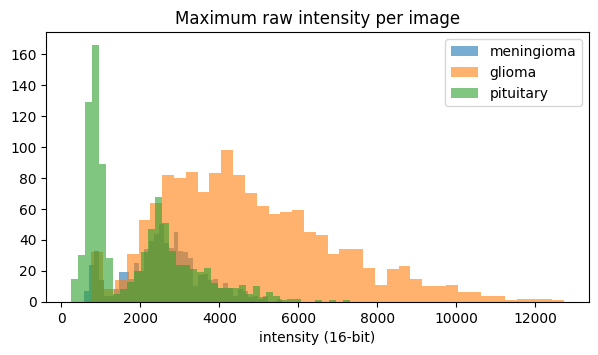

In [6]:
display(meta.groupby(["height", "width"]).size().rename("images").to_frame())
fig, ax = plt.subplots(figsize=(7, 3.5))
for name in CLASSES:
    ax.hist(meta.loc[meta.class_name == name, "max"], bins=40, alpha=0.6, label=name)
ax.set(title="Maximum raw intensity per image", xlabel="intensity (16-bit)")
ax.legend()
fig.savefig(FIG_DIR / "intensity_range.png", dpi=150, bbox_inches="tight")

## 4. Sample images per class (tumour mask in green)

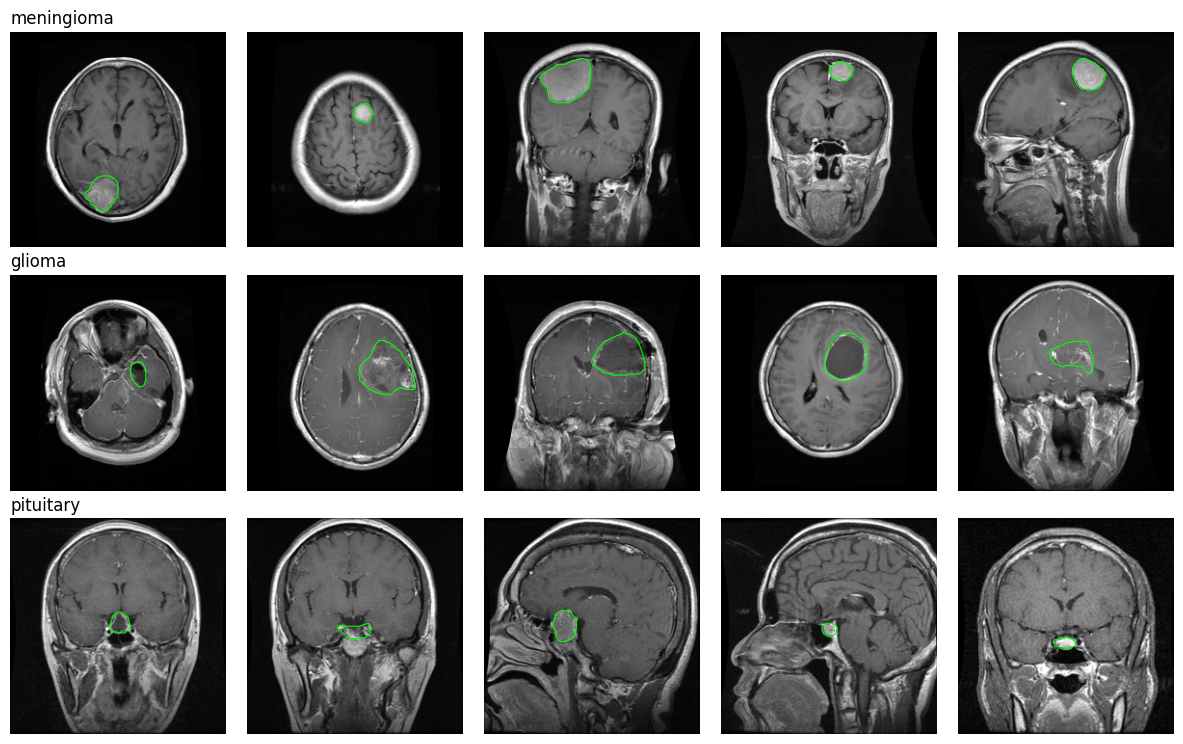

In [7]:
n = 5
fig, axes = plt.subplots(len(CLASSES), n, figsize=(2.4 * n, 2.5 * len(CLASSES)))
for r, name in enumerate(CLASSES):
    sample = meta[meta.class_name == name].sample(n, random_state=1)
    for c, image_id in enumerate(sample["image_id"]):
        img = np.load(processed / "images" / f"{image_id}.npy").astype(float)
        axes[r, c].imshow(img, cmap="gray")
        mask_path = processed / "masks" / f"{image_id}.npy"
        if mask_path.exists():
            axes[r, c].contour(np.load(mask_path), levels=[0.5], colors="lime", linewidths=0.8)
        axes[r, c].axis("off")
    axes[r, 0].set_title(name, loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "samples_per_class.png", dpi=150)

## 5. Tumour size per class

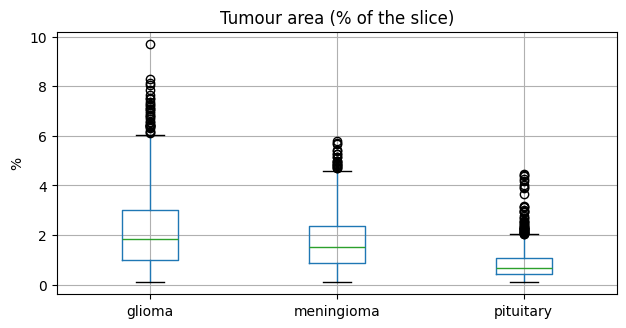

In [8]:
area_pct = 100 * meta["tumor_area"] / (meta["height"] * meta["width"])
ax = pd.DataFrame({"class": meta["class_name"], "area_pct": area_pct}).boxplot(
    by="class", column="area_pct", figsize=(7, 3.5))
ax.set(title="Tumour area (% of the slice)", xlabel="", ylabel="%")
plt.suptitle("")
ax.figure.savefig(FIG_DIR / "tumor_area.png", dpi=150, bbox_inches="tight")

## 6. The patient-level split

In [9]:
table = (splits.groupby(["split", "label"]).size().unstack()
         .rename(columns=dict(enumerate(CLASSES))).loc[["train", "val", "test"]])
table["images"] = table.sum(axis=1)
table["patients"] = splits.groupby("split")["patient_id"].nunique()
display(table)

leaky_train = set(splits.loc[splits.image_split == "train", "patient_id"])
leaky_test = splits[splits.image_split == "test"]
print(f"Image-level split: {leaky_test.patient_id.isin(leaky_train).mean():.1%} of test images "
      "come from patients seen in training (leakage).")

label,meningioma,glioma,pituitary,images,patients
split,,,,,
train,468,1010,672,2150,163
val,128,228,138,494,35
test,112,188,120,420,35


Image-level split: 99.6% of test images come from patients seen in training (leakage).
